# Produção ambulatorial de Ijuí (SIASUS)


## 1. Conexão com o MySQL

In [92]:
from getpass import getpass
from mysql.connector import connect, Error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")


def usar_conexao(acao):
    try:
        with connect(
            host="localhost",
            user=input("Usuário: "),
            password=getpass("Senha: ")
        ) as connection:
            print("Conexão estabelecida:", connection)
            return acao(connection)
    except Error as e:
        print("Ocorreu um erro ao conectar com o BD: ", e)

## 2. Carregar os dados da VIEW para um DataFrame
Todos os exemplos seguintes utilizam DataFrames derivados de `tabela`.

**Requisito de infraestrutura:** `fetchall()` carrega os registros na memória antes de construir o DataFrame.

In [93]:
import pandas as pd

# Consulta SQL única para recuperar todas as colunas e linhas da VIEW.
def carregar_dados(connection):
    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM dbsia.pa_ijui")
        return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

tabela = usar_conexao(carregar_dados)

display(tabela.head(10))

Usuário:  root
Senha:  ········


Conexão estabelecida: <mysql.connector.connection_cext.CMySQLConnection object at 0x1363eee50>


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,041,0000,CID NAO INFORMADO,IJUI,None,1,1,6.30,6.30
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,065,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,059,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,068,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,035,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
5,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,052,0000,CID NAO INFORMADO,IJUI,None,3,3,18.90,18.90
6,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,068,0000,CID NAO INFORMADO,IJUI,None,2,2,12.60,12.60
7,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA MEDICA EM ATENCAO PRIMARIA,Medico clinico,0,032,0000,CID NAO INFORMADO,IJUI,None,3,3,0.00,0.00
8,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,072,0000,CID NAO INFORMADO,IJUI,None,1,1,6.30,6.30
9,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA MEDICA EM ATENCAO PRIMARIA,Medico clinico,0,024,0000,CID NAO INFORMADO,IJUI,None,2,2,0.00,0.00


## 3. Análise Exploratória de Dados
* Verificar o número de linhas e colunas do banco de dados.
* Conferir tipos de variáveis (numéricas, categóricas, textuais).
* Calcular estatísticas descritivas iniciais (média, mediana, mínimo, máximo, distribuição de frequências).
* Identificar valores ausentes (por exemplo, NaN, campos vazios) e valores inválidos (por exemplo, idade fora da faixa, sexo diferente de M/F, CIDs não existentes).

### 3.1 Dimensão e tipos

In [94]:
print("Linhas:", tabela.shape[0])
print("Colunas:", tabela.shape[1])

# Quantidades e valores vêm do MySQL como Decimal e a idade como texto.
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
tabela[colunas_numericas] = tabela[colunas_numericas].apply(pd.to_numeric)
tabela["pa_idade"] = pd.to_numeric(tabela["pa_idade"], errors="coerce")

display(tabela.dtypes.to_frame("Tipo"))

Linhas: 70377
Colunas: 17


,Tipo
Ano,int64
Mes,int64
AnoBimestre,object
AnoTrimestre,object
Estabelecimento,object
Procedimento,object
Ocupacao,object
pa_sexo,object
pa_idade,int64
pa_cidpri,object


### 3.2 Estatísticas descritivas

In [95]:
display(tabela[colunas_numericas + ["pa_idade"]].describe())

print("Mediana:")
display(tabela[colunas_numericas + ["pa_idade"]].median().to_frame("Mediana"))

print("Estabelecimentos com mais registros:")
display(tabela["Estabelecimento"].value_counts().head(10))

print("Registros por sexo:")
display(tabela["pa_sexo"].value_counts())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr,pa_idade
count,70377.000000,70377.000000,70377.000000,70377.000000,70377.000000
mean,7.464015,5.667050,98.820903,97.194167,65.848516
std,54.591756,49.411909,634.935089,636.061808,111.889569
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.850000,0.000000,39.000000
50%,1.000000,1.000000,6.300000,3.370000,60.000000
75%,1.000000,1.000000,17.670000,10.900000,72.000000
max,6284.000000,5337.000000,60741.370000,60741.370000,999.000000


Mediana:


,Mediana
pa_qtdpro,1.00
pa_qtdapr,1.00
pa_valpro,6.30
pa_valapr,3.37
pa_idade,60.00


Estabelecimentos com mais registros:


Estabelecimento
HOSPITAL DE CLINICAS IJUI                                24265
HOSPITAL BOM PASTOR IJUI                                 19162
17 COORDENADORIA REGIONAL DE SAUDE                        7573
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE             4326
APAE IJUI                                                 3183
CER III UNIR                                              2838
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO     2825
CENTRO AUDITIVO PROAUDI                                   2354
CISA                                                      1766
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA               1048
Name: count, dtype: int64

Registros por sexo:


pa_sexo
F    34730
M    32857
0     2790
Name: count, dtype: int64

### 3.3 Valores ausentes e inválidos
O CID `0000` indica que o diagnóstico não foi informado. Quando o CID foi informado mas `Diagnostico` ficou vazio, o código não existe na tabela `S_CID`.

In [96]:
nulos = tabela.isna().sum()
display(nulos[nulos > 0].sort_values(ascending=False).to_frame("Nulos"))

idade_invalida = ~tabela["pa_idade"].between(0, 120)
sexo_invalido = ~tabela["pa_sexo"].isin(["M", "F"])
cid_inexistente = ~tabela["pa_cidpri"].isin(["", "0000"]) & tabela["Diagnostico"].isna()

invalidos = pd.DataFrame({
    "Problema": ["Idade fora de 0 a 120", "Sexo diferente de M/F", "CID não encontrado na S_CID"],
    "Registros": [idade_invalida.sum(), sexo_invalido.sum(), cid_inexistente.sum()]
})
display(invalidos)

print("Linhas duplicadas:", tabela.duplicated().sum())

,Nulos
MunicipioPaciente,2790
Diagnostico,9


,Problema,Registros
0,Idade fora de 0 a 120,955
1,Sexo diferente de M/F,2790
2,CID não encontrado na S_CID,9


Linhas duplicadas: 27880


## 4. Limpeza e Preparação dos Dados
* Aplicar estratégias para melhorar a qualidade dos dados:
* Valores nulos: apagar as linhas? preencher com "Não informado"?
* Duplicações: remover registros duplicados.

**Decisões:**
* Nulos em campos de texto foram preenchidos com "Não informado", assim os registros continuam contando na produção e nos valores.
* Sexo `0` passou a "Não informado" e idades fora de 0 a 120 ficaram nulas, para não distorcer médias e faixas etárias.
* As linhas repetidas não foram removidas com `drop_duplicates()`: a VIEW não tem um identificador do atendimento, então duas linhas iguais podem ser atendimentos diferentes (mesmo procedimento, profissional e idade). A duplicação real, causada pelo JOIN com `s_cid`, foi corrigida na origem (item 3.4).

In [97]:
colunas_texto = ["Estabelecimento", "Procedimento", "Ocupacao", "Diagnostico", "MunicipioPaciente"]
tabela[colunas_texto] = tabela[colunas_texto].fillna("Não informado")

tabela["Sexo"] = tabela["pa_sexo"].map({"M": "Masculino", "F": "Feminino"}).fillna("Não informado")
tabela["pa_idade"] = tabela["pa_idade"].where(tabela["pa_idade"].between(0, 120))

nulos = tabela.isna().sum()
display(nulos[nulos > 0].to_frame("Nulos após a limpeza"))
display(tabela.head())

,Nulos após a limpeza
pa_idade,955


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr,Sexo
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,41.0,0000,CID NAO INFORMADO,IJUI,Não informado,1,1,6.3,6.3,Não informado
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,65.0,0000,CID NAO INFORMADO,IJUI,Não informado,3,3,18.9,18.9,Não informado
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,59.0,0000,CID NAO INFORMADO,IJUI,Não informado,3,3,18.9,18.9,Não informado
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,68.0,0000,CID NAO INFORMADO,IJUI,Não informado,3,3,18.9,18.9,Não informado
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,35.0,0000,CID NAO INFORMADO,IJUI,Não informado,3,3,18.9,18.9,Não informado


## 5. Análises Estratégicas para o Gestor de Saúde do Município

### 5.1 Volume e Perfil dos Procedimentos
* Quantos procedimentos ambulatoriais foram realizados em Ijuí no último mês, bimestre e trimestre (crie a tabela de granularidade temporal a partir do arquivo 04-gera-dimtempo-mysql.sql).
* Distribuição por especialidade/procedimento (consultas básicas, exames de imagem, oncologia, psiquiatria, etc).
* Evolução temporal: picos e quedas na demanda.

A VIEW já traz `Ano`, `Mes`, `AnoBimestre` e `AnoTrimestre` vindos da dimensão de tempo. A ocupação do profissional (CBO) foi usada como especialidade.

In [98]:
anomes = pd.to_numeric(tabela["Ano"]) * 100 + pd.to_numeric(tabela["Mes"])

periodos = {
    "Último mês": tabela[anomes == anomes.max()],
}

volume = pd.DataFrame([
    {
        "Período": nome,
        "Registros": len(dados),
        "QuantidadeApresentada": dados["pa_qtdpro"].sum(),
        "QuantidadeAprovada": dados["pa_qtdapr"].sum()
    }
    for nome, dados in periodos.items()
])

display(volume)

,Período,Registros,QuantidadeApresentada,QuantidadeAprovada
0,Último mês,70377,525295,398830


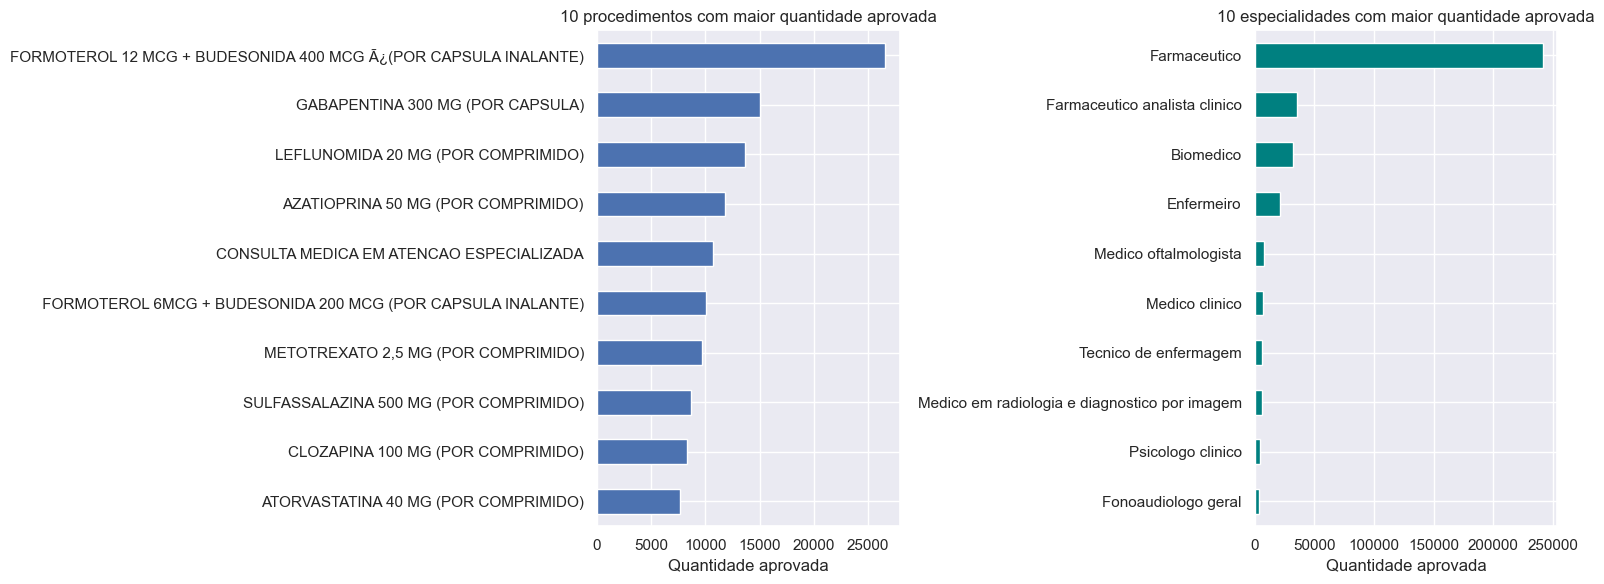

In [99]:
procedimentos = (
    tabela.groupby("Procedimento", as_index=False)["pa_qtdapr"].sum()
    .sort_values("pa_qtdapr", ascending=False)
)
especialidades = (
    tabela.groupby("Ocupacao", as_index=False)["pa_qtdapr"].sum()
    .sort_values("pa_qtdapr", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

procedimentos.head(10).sort_values("pa_qtdapr").plot(
    x="Procedimento", y="pa_qtdapr", kind="barh", ax=axes[0], legend=False
)
axes[0].set_title("10 procedimentos com maior quantidade aprovada")
axes[0].set_xlabel("Quantidade aprovada")
axes[0].set_ylabel("")

especialidades.head(10).sort_values("pa_qtdapr").plot(
    x="Ocupacao", y="pa_qtdapr", kind="barh", ax=axes[1], legend=False, color="teal"
)
axes[1].set_title("10 especialidades com maior quantidade aprovada")
axes[1].set_xlabel("Quantidade aprovada")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Evolução temporal.** Com apenas um mês carregado (PARS2607) o gráfico mostra um ponto só; ao carregar outras competências ele passa a mostrar os picos e quedas.

### 5.2 Produção por Estabelecimento de Saúde
* Ranking de produção dos estabelecimentos (HCI, Hospital Bom Pastor, UBS, clínicas conveniadas).
* Comparar volume de procedimentos aprovados x produzidos.

No SIA, "produzido" corresponde ao **apresentado** (`pa_qtdpro`).

In [100]:
estabelecimentos = (
    tabela.groupby("Estabelecimento", as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"))
    .sort_values("QuantidadeAprovada", ascending=False)
)
estabelecimentos["Diferenca"] = estabelecimentos["QuantidadeApresentada"] - estabelecimentos["QuantidadeAprovada"]
estabelecimentos["PercentualAprovado"] = (
    estabelecimentos["QuantidadeAprovada"] / estabelecimentos["QuantidadeApresentada"] * 100
).round(1)

display(estabelecimentos.head(15))

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,Diferenca,PercentualAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,7573,337855,241727,96128,71.5
11,HOSPITAL DE CLINICAS IJUI,24265,45902,38131,7771,83.1
12,LABORATORIO DE ANALISES CLINICAS UNILAB,300,29720,29720,0,100.0
8,CISA,1766,30553,24659,5894,80.7
17,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,235,24915,21566,3349,86.6
10,HOSPITAL BOM PASTOR IJUI,19162,19166,10173,8993,53.1
9,HEMOVITA,159,8117,8117,0,100.0
4,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4326,8005,5184,2821,64.8
5,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,2825,4215,3447,768,81.8
3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1048,3494,3324,170,95.1


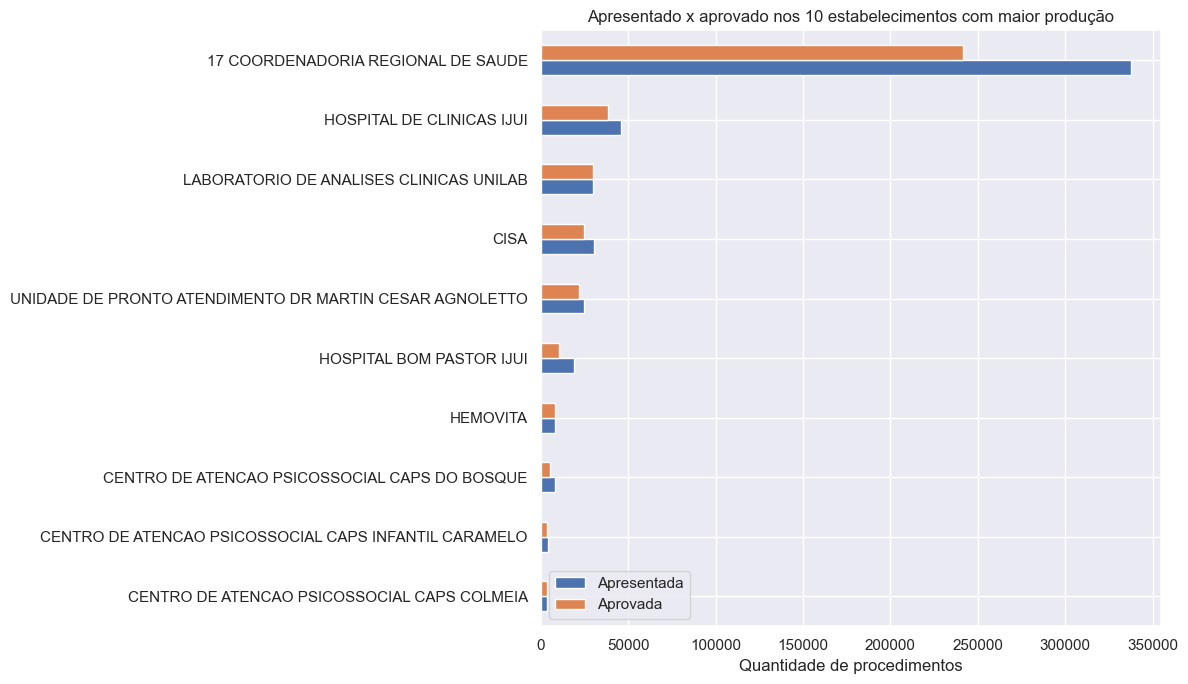

In [101]:
estabelecimentos.head(10).sort_values("QuantidadeAprovada").plot(
    x="Estabelecimento", y=["QuantidadeApresentada", "QuantidadeAprovada"],
    kind="barh", figsize=(12, 7)
)
plt.title("Apresentado x aprovado nos 10 estabelecimentos com maior produção")
plt.xlabel("Quantidade de procedimentos")
plt.ylabel("")
plt.legend(["Apresentada", "Aprovada"])
plt.tight_layout()
plt.show()

### 5.3 Perfil Demográfico e Epidemiológico da População Atendida
* Distribuição por sexo e faixa etária.
* Principais diagnósticos (CID) atendidos (hipertensão, diabetes, câncer, etc).

As contagens são de **registros**, não de pacientes distintos.

,Registros
Sexo,
Feminino,34730
Masculino,32857
Não informado,2790


,Registros
FaixaEtaria,
0-17,9535
18-39,8079
40-59,17458
60-79,28747
80+,5603


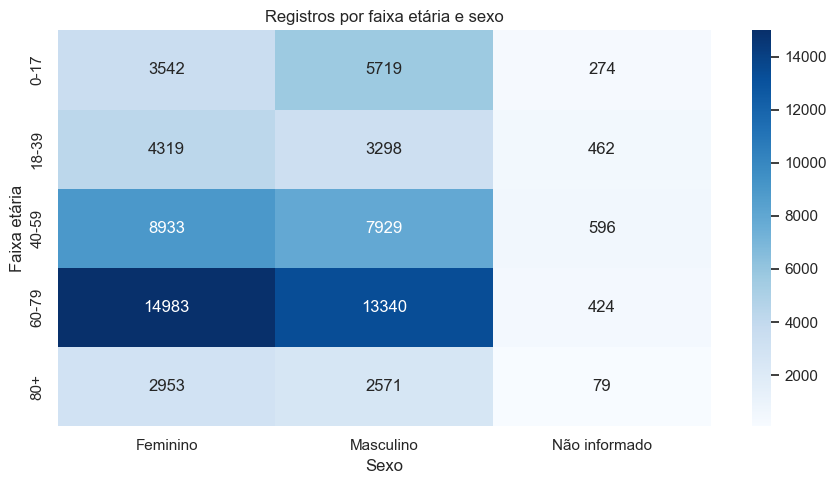

In [102]:
tabela["FaixaEtaria"] = pd.cut(
    tabela["pa_idade"],
    bins=[-1, 17, 39, 59, 79, 120],
    labels=["0-17", "18-39", "40-59", "60-79", "80+"]
)

display(tabela["Sexo"].value_counts().to_frame("Registros"))
display(tabela["FaixaEtaria"].value_counts().sort_index().to_frame("Registros"))

matriz = pd.crosstab(tabela["FaixaEtaria"], tabela["Sexo"])

plt.figure(figsize=(9, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues")
plt.title("Registros por faixa etária e sexo")
plt.xlabel("Sexo")
plt.ylabel("Faixa etária")
plt.tight_layout()
plt.show()

Registros com CID informado: 23573 de 70377


,Registros
Diagnostico,
H90.5 Perda de audicao neuro-sensorial NE,2228
CID NÃO IDENTIFICADO,1553
F84.9 Transt globais NE do desenvolv,1323
I51.6 Doenc cardiovascular NE,1204
F84.0 Autismo infantil,1082
R52.0 Dor aguda,795
J45.0 Asma predom alergica,782
C50.1 Porcao central da mama,618
F71.0 Mencao ausencia de ou compr minimo comport,571


,Grupo,Registros
0,Hipertensão (I10-I15),1
1,Diabetes (E10-E14),541
2,Neoplasias malignas (C00-C97),2279


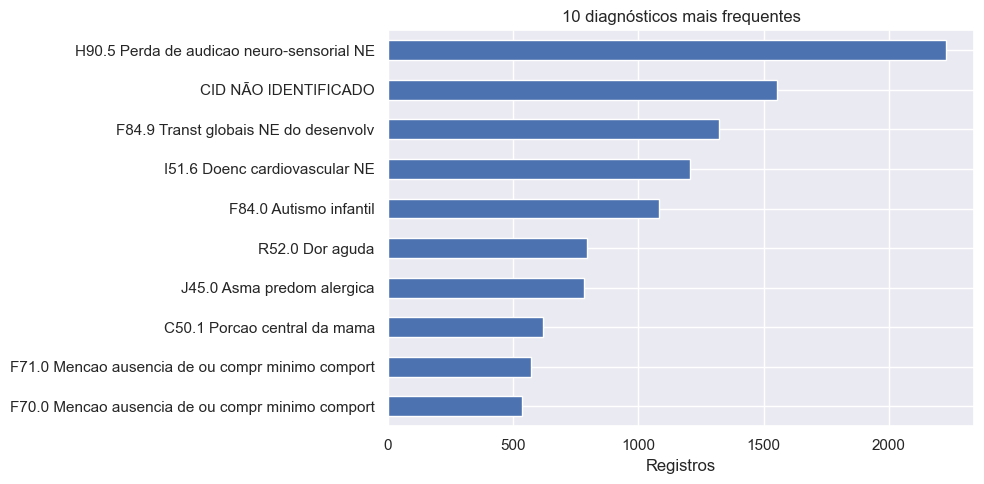

In [103]:
com_cid = tabela[~tabela["pa_cidpri"].isin(["", "0000"])]
print(f"Registros com CID informado: {len(com_cid)} de {len(tabela)}")

top_diagnosticos = com_cid["Diagnostico"].value_counts().head(10)
display(top_diagnosticos.to_frame("Registros"))

cid = com_cid["pa_cidpri"].str.upper()
grupos_cid = pd.DataFrame({
    "Grupo": ["Hipertensão (I10-I15)", "Diabetes (E10-E14)", "Neoplasias malignas (C00-C97)"],
    "Registros": [
        cid.str.match(r"I1[0-5]").sum(),
        cid.str.match(r"E1[0-4]").sum(),
        cid.str.startswith("C").sum(),
    ]
})
display(grupos_cid)

top_diagnosticos.sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("10 diagnósticos mais frequentes")
plt.xlabel("Registros")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 5.4 Fluxos Regionais e Acesso
* Municípios de origem dos pacientes atendidos em Ijuí.
* Quantos atendimentos feitos em Ijuí são de moradores de outros municípios.

In [104]:
municipios = tabela["MunicipioPaciente"].value_counts()
display(municipios.head(15).to_frame("Registros"))


def classificar_origem(municipio):
    if municipio == "Não informado":
        return "Não informado"
    if "IJUI" in municipio.upper():
        return "Ijuí"
    return "Outros municípios"


tabela["OrigemPaciente"] = tabela["MunicipioPaciente"].apply(classificar_origem)

origem = (
    tabela.groupby("OrigemPaciente", as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeAprovada=("pa_qtdapr", "sum"))
)
origem["PercentualRegistros"] = (origem["Registros"] / origem["Registros"].sum() * 100).round(1)
display(origem)

,Registros
MunicipioPaciente,
IJUI,34647
PANAMBI,3351
Não informado,2790
JOIA,2609
CRISSIUMAL,1924
CATUIPE,1865
SANTO AUGUSTO,1800
AUGUSTO PESTANA,1712
CONDOR,1289


,OrigemPaciente,Registros,QuantidadeAprovada,PercentualRegistros
0,Ijuí,34754,116286,49.4
1,Não informado,2790,111016,4.0
2,Outros municípios,32833,171528,46.7


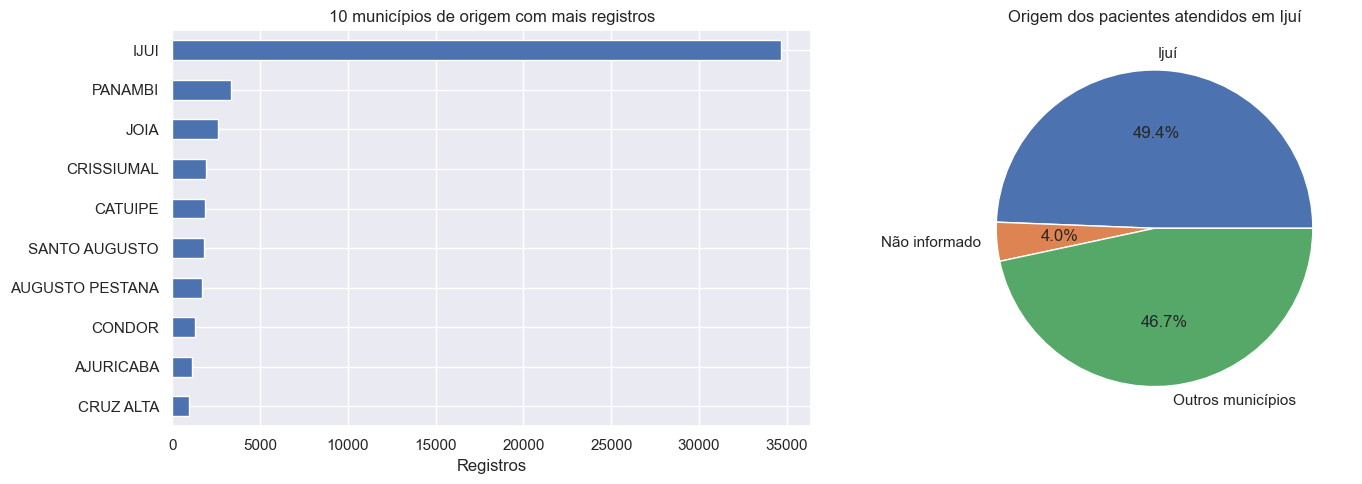

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

municipios.drop("Não informado", errors="ignore").head(10).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("10 municípios de origem com mais registros")
axes[0].set_xlabel("Registros")
axes[0].set_ylabel("")

origem.set_index("OrigemPaciente")["Registros"].plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Origem dos pacientes atendidos em Ijuí")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 5.5 Recursos Financeiros
* Total de valores aprovados pelo SUS para Ijuí x valores produzidos.
* Diferença entre produzidos e aprovados.
* Evolução do gasto médio por procedimento ambulatorial.

In [106]:
total_produzido = tabela["pa_valpro"].sum()
total_aprovado = tabela["pa_valapr"].sum()

financeiro = pd.DataFrame({
    "Indicador": ["Valor produzido (apresentado)", "Valor aprovado", "Diferença", "Percentual aprovado"],
    "Valor": [total_produzido, total_aprovado, total_produzido - total_aprovado,
              total_aprovado / total_produzido * 100]
})
display(financeiro.round(2))

mensal["GastoMedio"] = mensal["ValorAprovado"] / mensal["QuantidadeAprovada"]
mensal["Diferenca"] = mensal["ValorApresentado"] - mensal["ValorAprovado"]
display(mensal[["AnoMes", "ValorApresentado", "ValorAprovado", "Diferenca", "GastoMedio"]].round(2))

,Indicador,Valor
0,Valor produzido (apresentado),6954718.70
1,Valor aprovado,6840233.87
2,Diferença,114484.83
3,Percentual aprovado,98.35


,AnoMes,ValorApresentado,ValorAprovado,Diferenca,GastoMedio
0,202607,6954718.7,6840233.87,114484.83,17.15


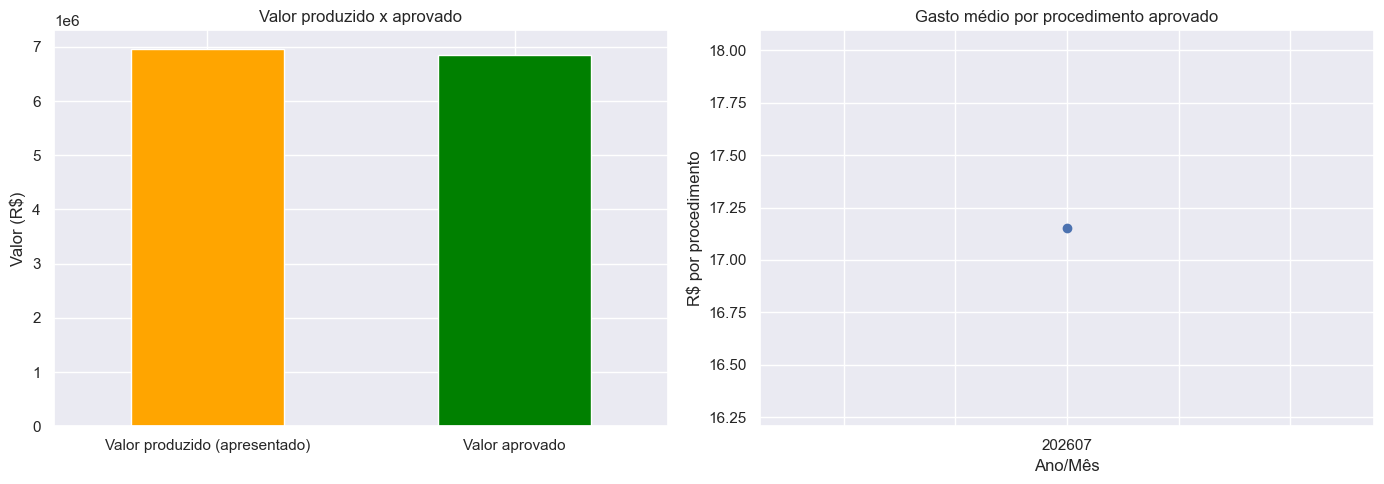

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

financeiro.iloc[:2].plot(x="Indicador", y="Valor", kind="bar", ax=axes[0], legend=False, color=["orange", "green"])
axes[0].set_title("Valor produzido x aprovado")
axes[0].set_xlabel("")
axes[0].set_ylabel("Valor (R$)")
axes[0].tick_params(axis="x", rotation=0)

mensal.plot(x="AnoMes", y="GastoMedio", kind="line", marker="o", ax=axes[1], legend=False)
axes[1].set_title("Gasto médio por procedimento aprovado")
axes[1].set_xlabel("Ano/Mês")
axes[1].set_ylabel("R$ por procedimento")

plt.tight_layout()
plt.show()

### 5.6 Foco em Áreas Críticas
* Oncologia: quimioterapia e radioterapia (aprovados x produzidos).
* Saúde mental: atendimentos psiquiátricos e psicológicos.
* Atenção básica: consultas e procedimentos nas UBS, acompanhamento de doenças crônicas.

As áreas foram identificadas por palavras-chave na descrição do procedimento, do estabelecimento e da ocupação. Um registro pode entrar em mais de uma área.

Ijuí não tem UBS informando produção no SIA: a produção das UBS vai para o SISAB (e-SUS APS). Aqui a atenção básica aparece por procedimentos típicos (consulta em atenção primária, aferição de pressão, glicemia capilar, acolhimento à demanda espontânea). A análise pela complexidade do procedimento está no item 6.4.

In [108]:
procedimento = tabela["Procedimento"].str.upper()
estabelecimento = tabela["Estabelecimento"].str.upper()
ocupacao = tabela["Ocupacao"].str.upper()
cid = tabela["pa_cidpri"].str.upper()

areas = {
    "Quimioterapia": procedimento.str.contains("QUIMIOTERAPIA"),
    "Radioterapia": procedimento.str.contains("RADIOTERAPIA|RADIOCIRURGIA|BRAQUITERAPIA"),
    "Saúde mental": (
        estabelecimento.str.contains("CAPS|PSICOSSOCIAL")
        | ocupacao.str.contains("PSIQUIATRA|PSICOLOGO")
        | procedimento.str.contains("PSICOSSOCIAL|PSIQUIATR|PSICOTERAPIA")
    ),
    "Atenção básica": procedimento.str.contains("ATENCAO PRIMARIA|ATENCAO BASICA|AFERICAO DE PRESSAO|GLICEMIA CAPILAR|DEMANDA ESPONTANEA"),
    "Doenças crônicas (HAS/DM)": cid.str.match(r"I1[0-5]|E1[0-4]"),
}

resumo_areas = pd.DataFrame([
    {"Area": nome,
     "Registros": filtro.sum(),
     "QuantidadeApresentada": tabela.loc[filtro, "pa_qtdpro"].sum(),
     "QuantidadeAprovada": tabela.loc[filtro, "pa_qtdapr"].sum(),
     "ValorApresentado": tabela.loc[filtro, "pa_valpro"].sum(),
     "ValorAprovado": tabela.loc[filtro, "pa_valapr"].sum()}
    for nome, filtro in areas.items()
])
resumo_areas["DiferencaValor"] = resumo_areas["ValorApresentado"] - resumo_areas["ValorAprovado"]
display(resumo_areas.round(2))

,Area,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado,DiferencaValor
0,Quimioterapia,694,608,608,919223.05,919223.05,0.0
1,Radioterapia,212,236,235,822873.30,819131.70,3741.6
2,Saúde mental,10243,18194,14360,50124.00,49647.80,476.2
3,Atenção básica,321,10454,10454,0.00,0.00,0.0
4,Doenças crônicas (HAS/DM),542,5500,2647,1729.51,1729.51,0.0


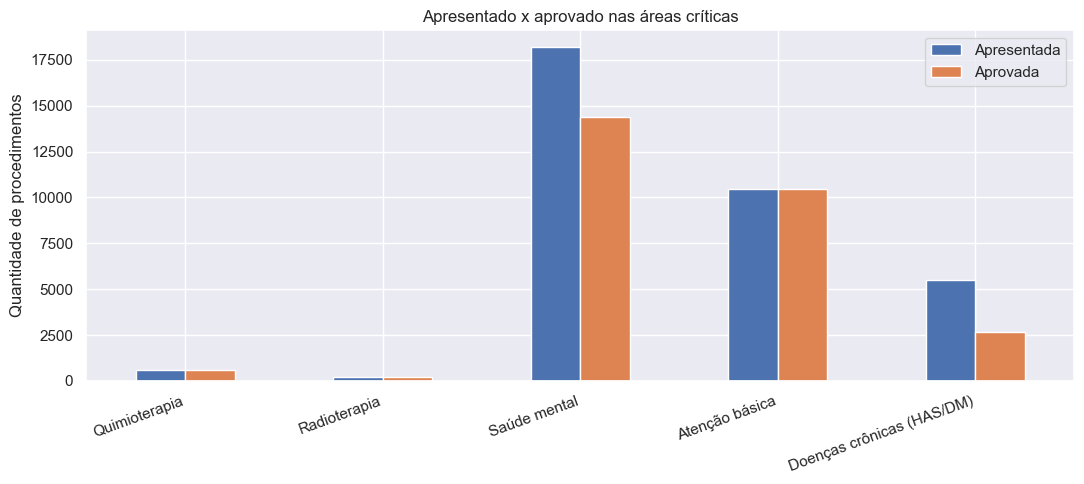

In [109]:
resumo_areas.set_index("Area")[["QuantidadeApresentada", "QuantidadeAprovada"]].plot(kind="bar", figsize=(11, 5))
plt.title("Apresentado x aprovado nas áreas críticas")
plt.xlabel("")
plt.ylabel("Quantidade de procedimentos")
plt.xticks(rotation=20, ha="right")
plt.legend(["Apresentada", "Aprovada"])
plt.tight_layout()
plt.show()

In [110]:
for nome in ["Quimioterapia", "Radioterapia", "Saúde mental", "Atenção básica"]:
    dados = tabela[areas[nome]]
    print(f"{nome}: {len(dados)} registros")
    if dados.empty:
        continue
    por_area = (
        dados.groupby(["Estabelecimento", "Procedimento"], as_index=False)
        .agg(QuantidadeApresentada=("pa_qtdpro", "sum"),
             QuantidadeAprovada=("pa_qtdapr", "sum"),
             ValorAprovado=("pa_valapr", "sum"))
        .sort_values("QuantidadeAprovada", ascending=False)
    )
    display(por_area.head(10))

Quimioterapia: 694 registros


,Estabelecimento,Procedimento,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
46,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RE...,79,79,83949.35
17,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RAR...,69,69,10350.00
59,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO CARCINOMA DE RETO AVANCADO -1...,33,33,73392.00
10,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DA LEUCEMIA MIELOIDE CRONICA EM ...,32,32,544.00
30,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DE MIELOMA MULTIPLO ? 1Â¦ LINHA,32,32,167188.80
42,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO ADENOCARCINOMA DE COLON AVANC...,24,24,53376.00
13,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DE ADENOCARCINOMA DE COLON,24,24,53376.00
50,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO CARCINOMA DE MAMA (PREVIA),23,23,32200.00
62,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO CARCINOMA EPIDERMOIDE / ADENO...,18,18,23400.00
71,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA INTRA-VESICAL,13,13,16900.00


Radioterapia: 212 registros


,Estabelecimento,Procedimento,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
9,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE PLASMOCITOMA / MIELOMA / METAS...,39,39,80917.2
0,HOSPITAL DE CLINICAS IJUI,HORMONIOTERAPIA ADJUVANTE A RADIOTERAPIA EXTER...,34,34,10251.0
1,HOSPITAL DE CLINICAS IJUI,HORMONIOTERAPIA PREVIA A RADIOTERAPIA EXTERNA ...,33,33,9949.5
6,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE MAMA,29,29,205459.2
10,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE PROSTATA,23,23,161128.8
8,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE PELE,14,14,38808.0
12,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DO APARELHO DIGESTIVO,14,14,69686.4
4,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE CANCER GINECOLOGICO,12,12,66355.2
5,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE LINFOMA E LEUCEMIA,10,10,37908.0
2,HOSPITAL DE CLINICAS IJUI,RADIOTERAPIA DE CABECA E PESCOCO,8,8,40012.8


Saúde mental: 10243 registros


,Estabelecimento,Procedimento,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
0,APAE IJUI,ACOMPANHAMENTO NEUROPSICOLOGICO DE PACIENTE EM...,1242,1242,21946.14
35,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,ACOLHIMENTO DIURNO DE PACIENTE EM CENTRO DE AT...,1188,1188,0.00
38,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,ATENDIMENTO EM GRUPO DE PACIENTE EM CENTRO DE ...,1373,850,0.00
22,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,737,737,4643.10
41,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,734,734,4624.20
40,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,ATENDIMENTO INDIVIDUAL DE PACIENTE EM CENTRO D...,704,704,0.00
75,CISA,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,510,510,5100.00
49,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,ACOES DE REABILITACAO PSICOSSOCIAL,899,500,0.00
63,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,PROMOCAO DE CONTRATUALIDADE NO TERRITORIO,498,498,0.00
62,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,PRATICAS EXPRESSIVAS E COMUNICATIVAS,492,492,0.00


Atenção básica: 321 registros


,Estabelecimento,Procedimento,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
22,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,AFERICAO DE PRESSAO ARTERIAL,4628,4628,0.0
12,CISA,CONSULTA MEDICA EM ATENCAO PRIMARIA,2390,2390,0.0
24,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,GLICEMIA CAPILAR,1289,1289,0.0
2,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,ESCUTA INICIAL / ORIENTACAO (ACOLHIMENTO A DEM...,449,449,0.0
6,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,ESCUTA INICIAL / ORIENTACAO (ACOLHIMENTO A DEM...,312,312,0.0
1,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,310,310,0.0
5,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA MEDICA EM ATENCAO PRIMARIA,163,163,0.0
4,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,147,147,0.0
8,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,105,105,0.0
20,SAMU 192 SB46 IJUI,AFERICAO DE PRESSAO ARTERIAL,90,90,0.0


## 6. Perguntas do gestor: como apresentar resultados significativos

Um resultado só é significativo para o gestor quando responde a uma pergunta concreta com um número que dá para comparar e confiar. Os critérios que usei:

1. **Indicador definido antes do gráfico.** Cada pergunta vira uma medida: registros, quantidade aprovada ou valor (R$). Dizer qual é.
2. **Medida certa.** Produção é a **quantidade aprovada** (`pa_qtdapr`), não o número de linhas: uma linha de BPA consolidado pode ter centenas de procedimentos.
3. **Comparação com denominador.** Percentuais (aprovado/apresentado, % de pacientes de fora) dizem mais que totais soltos. Para comparar municípios, taxa por habitante (população do IBGE).
4. **Período comparável.** A base tem só julho de 2026. Um mês mostra o retrato, não a tendência; para picos e sazonalidade são necessários 12 meses ou mais.
5. **Qualidade junto do resultado.** Informar quanto do campo está "não informado" (por exemplo, o BPA consolidado não tem idade, sexo nem município).
6. **Fonte certa para cada pergunta.** O SIA registra só a produção **ambulatorial**. Internação está no SIH, a atenção básica das UBS no SISAB, a estrutura dos estabelecimentos no CNES e a renda no IBGE/CadÚnico.
7. **Visual simples.** Top 10 em barras horizontais ordenadas, título que responde à pergunta e unidade no eixo.
8. **Limitações explícitas.** Quando o dado não existe, dizer isso e indicar onde buscar, em vez de forçar uma resposta.

### O que a base permite responder

| Pergunta | Dá para responder com o SIA? | Campo usado | O que mais seria necessário |
|---|---|---|---|
| Hospital que mais atende emergências | Sim | `pa_catend` (02 a 06) e procedimentos de urgência | SIH para urgências que viram internação |
| Quem faz mais cirurgias | Sim, as ambulatoriais | grupo 04 do `pa_proc_id` | SIH (AIH) para cirurgias com internação |
| Quem tem mais pacientes internados | **Não** | só "observação até 24 horas" | SIH/SUS (arquivos RD) e leitos do CNES |
| Quem faz mais atendimento básico | Parcial | `pa_nivcpl = 1` | SISAB / e-SUS APS (produção das UBS) |
| Duração dos atendimentos básicos | **Não** | nenhum campo de horário | e-SUS APS ou prontuário com hora de início e fim |
| Cidade de origem | Sim | `pa_munpcn` | — |
| Bairro de origem | **Não** | o campo `BAIRRO` da `cadgerrs` está vazio para Ijuí | endereço do paciente (CadSUS/e-SUS) ou CNES completo |
| Faixa etária | Sim | `pa_idade` | — |
| Faixa de renda | **Não** | raça/cor é o único dado social | CadÚnico ou Censo IBGE por setor censitário |
| Maiores valores apresentados e não aprovados | Sim | `pa_valpro - pa_valapr` | relatório de críticas/glosas do SIA para o motivo |

### 6.1 Preparação da base complementar

In [111]:
for coluna in ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]:
    detalhe[coluna] = pd.to_numeric(detalhe[coluna])
detalhe["pa_idade"] = pd.to_numeric(detalhe["pa_idade"], errors="coerce")

colunas_texto = ["Estabelecimento", "BairroEstabelecimento", "Procedimento", "MunicipioPaciente"]
detalhe[colunas_texto] = detalhe[colunas_texto].replace("", pd.NA).fillna("Não informado")

detalhe["Grupo"] = detalhe["pa_proc_id"].str[:2]
detalhe["NaoAprovado"] = detalhe["pa_valpro"] - detalhe["pa_valapr"]

carater = {"01": "Eletivo", "02": "Urgência", "03": "Acidente de trabalho", "04": "Acidente de trajeto",
           "05": "Acidente de trânsito", "06": "Outras lesões/envenenamentos"}
detalhe["Carater"] = detalhe["pa_catend"].map(carater).fillna("Não informado (BPA consolidado)")

raca = {"01": "Branca", "02": "Preta", "03": "Parda", "04": "Amarela", "05": "Indígena"}
detalhe["RacaCor"] = detalhe["pa_racacor"].map(raca).fillna("Sem informação")

# Idade só vale para registros individualizados; o BPA consolidado não identifica o paciente.
individual = detalhe["pa_docorig"] != "C"
detalhe["FaixaEtaria"] = pd.cut(
    detalhe["pa_idade"].where(individual & detalhe["pa_idade"].between(0, 120)),
    bins=[-1, 17, 39, 59, 79, 120],
    labels=["0-17", "18-39", "40-59", "60-79", "80+"]
)


def resumo_por_estabelecimento(dados):
    return (
        dados.groupby("Estabelecimento", as_index=False)
        .agg(Registros=("pa_qtdapr", "size"),
             QuantidadeApresentada=("pa_qtdpro", "sum"),
             QuantidadeAprovada=("pa_qtdapr", "sum"),
             ValorAprovado=("pa_valapr", "sum"))
        .sort_values("QuantidadeAprovada", ascending=False)
    )


def grafico_top(resumo, coluna, titulo, rotulo):
    resumo.head(10).sort_values(coluna).plot(
        x="Estabelecimento", y=coluna, kind="barh", figsize=(11, 5), legend=False
    )
    plt.title(titulo)
    plt.xlabel(rotulo)
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


display(detalhe["Carater"].value_counts().to_frame("Registros"))

,Registros
Carater,
Eletivo,55680
Urgência,10354
Não informado (BPA consolidado),2790
Acidente de trajeto,2
Acidente de trabalho,1


### 6.2 Qual hospital mais atende emergências?
Usei dois critérios, porque cada um enxerga uma parte:
* **Caráter de urgência** (`pa_catend` 02 a 06): só existe nos registros individualizados (BPA-I e APAC).
* **Procedimentos de urgência** (descrição com "URGENCIA" ou "EMERGENCIA"): pega também o BPA consolidado, que é como a UPA informa boa parte da produção.

Pelo caráter de atendimento:


,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
3,HOSPITAL DE CLINICAS IJUI,8881,8920,5479,112256.41
2,HOSPITAL BOM PASTOR IJUI,1307,1308,815,6243.38
6,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,140,140,140,0.00
4,SAMU 192 SA16 IJUI,13,13,13,0.00
5,SAMU 192 SB46 IJUI,12,12,12,0.00


Pelos procedimentos de urgência:


,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
4,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,1,4871,4871,60741.37
3,HOSPITAL DE CLINICAS IJUI,42,2602,1987,22303.10
2,HOSPITAL BOM PASTOR IJUI,290,290,290,3373.75
0,CENTRO DE REFERENCIA REGIONAL EM SAUDE DO TRAB...,2,2,2,0.00
1,CISA,1,6,1,11.00


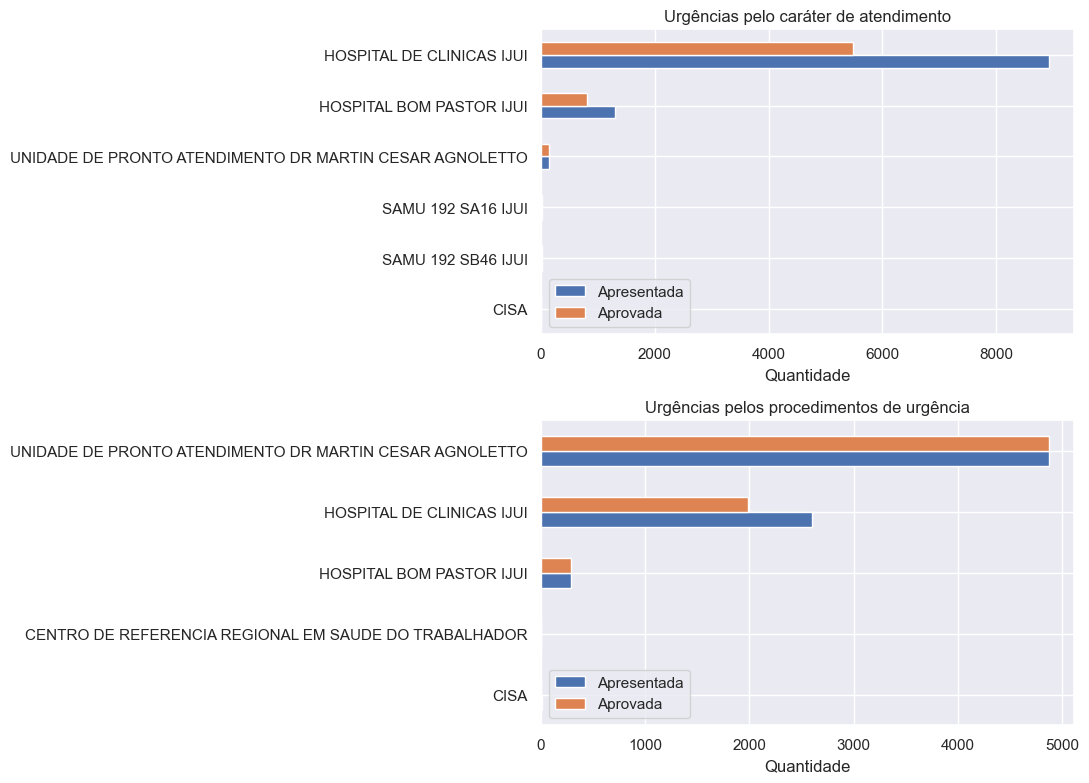

In [112]:
por_carater = resumo_por_estabelecimento(detalhe[detalhe["pa_catend"].isin(["02", "03", "04", "05", "06"])])
por_procedimento = resumo_por_estabelecimento(
    detalhe[detalhe["Procedimento"].str.contains("URGENCIA|EMERGENCIA", na=False)]
)

print("Pelo caráter de atendimento:")
display(por_carater.head(5))
print("Pelos procedimentos de urgência:")
display(por_procedimento.head(5))

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

por_carater.head(6).sort_values("QuantidadeAprovada").plot(
    x="Estabelecimento", y=["QuantidadeApresentada", "QuantidadeAprovada"], kind="barh", ax=axes[0]
)
axes[0].set_title("Urgências pelo caráter de atendimento")
axes[0].set_xlabel("Quantidade")
axes[0].set_ylabel("")
axes[0].legend(["Apresentada", "Aprovada"])

por_procedimento.head(6).sort_values("QuantidadeAprovada").plot(
    x="Estabelecimento", y=["QuantidadeApresentada", "QuantidadeAprovada"], kind="barh", ax=axes[1]
)
axes[1].set_title("Urgências pelos procedimentos de urgência")
axes[1].set_xlabel("Quantidade")
axes[1].set_ylabel("")
axes[1].legend(["Apresentada", "Aprovada"])

plt.tight_layout()
plt.show()

### 6.3 Qual faz mais cirurgias?
Procedimentos do grupo 04 da tabela SIGTAP (procedimentos cirúrgicos) registrados no ambulatório. Comparo quantidade e valor, porque quem faz mais cirurgias nem sempre é quem faz as mais caras.

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
4,HOSPITAL DE CLINICAS IJUI,779,841,841,31536.97
1,CER III UNIR,43,412,412,13348.80
3,HOSPITAL BOM PASTOR IJUI,304,304,304,353896.18
2,CISA,9,43,43,194.08
0,CENTRO AUDITIVO PROAUDI,1,40,40,225.20
5,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,2,6,6,0.00


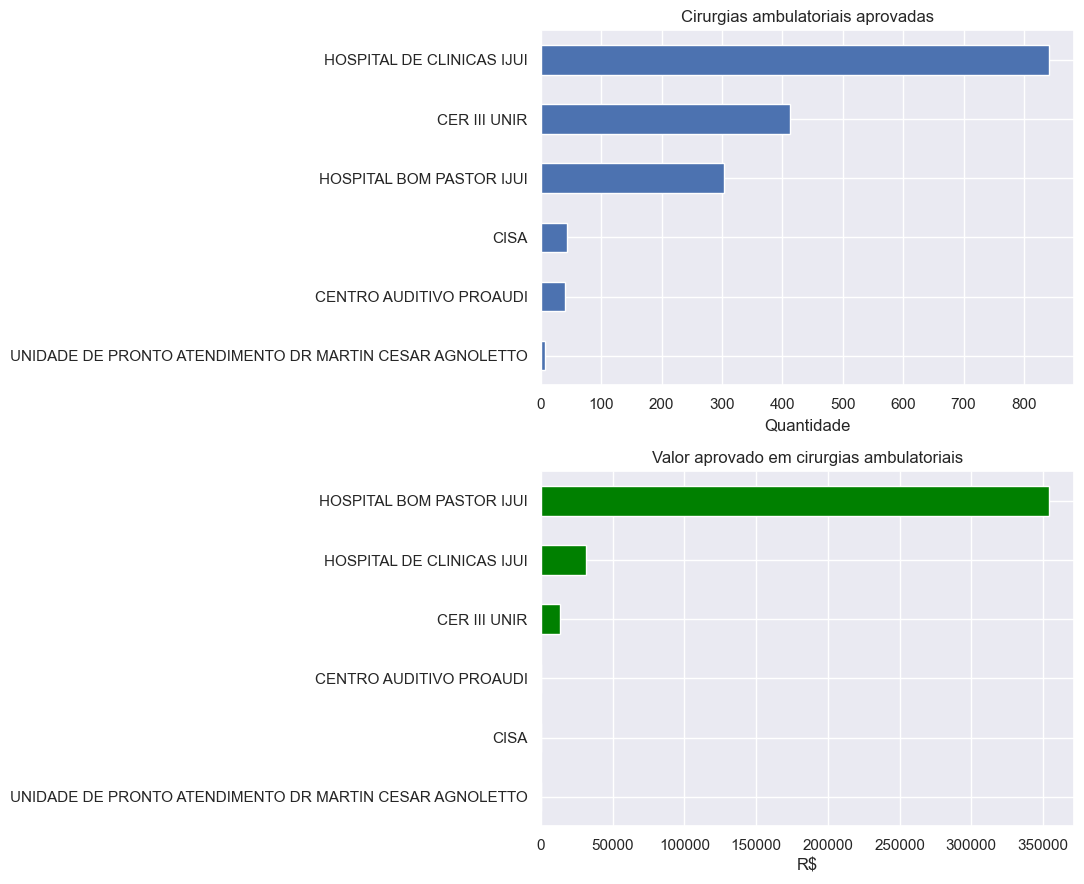

In [113]:
cirurgias = resumo_por_estabelecimento(detalhe[detalhe["Grupo"] == "04"])
display(cirurgias.head(10))

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

cirurgias.head(8).sort_values("QuantidadeAprovada").plot(
    x="Estabelecimento", y="QuantidadeAprovada", kind="barh", ax=axes[0], legend=False
)
axes[0].set_title("Cirurgias ambulatoriais aprovadas")
axes[0].set_xlabel("Quantidade")
axes[0].set_ylabel("")

cirurgias.sort_values("ValorAprovado", ascending=False).head(8).sort_values("ValorAprovado").plot(
    x="Estabelecimento", y="ValorAprovado", kind="barh", ax=axes[1], legend=False, color="green"
)
axes[1].set_title("Valor aprovado em cirurgias ambulatoriais")
axes[1].set_xlabel("R$")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 6.4 Qual tem mais pacientes internados?
O SIA não registra internações; elas estão no **SIH/SUS** (AIH, arquivos RD do DATASUS). O mais próximo que existe aqui é o "atendimento de urgência com observação até 24 horas", que mostra onde o paciente fica em observação sem ser internado.

O campo `pa_motsai = 21` ("permanência por características próprias da doença") parece internação, mas indica continuidade de tratamento em APAC (quimioterapia, terapia renal, reabilitação), não leito ocupado.

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
2,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,1,4871,4871,60741.37
1,HOSPITAL DE CLINICAS IJUI,24,1227,730,9103.10
0,HOSPITAL BOM PASTOR IJUI,125,125,125,1558.75


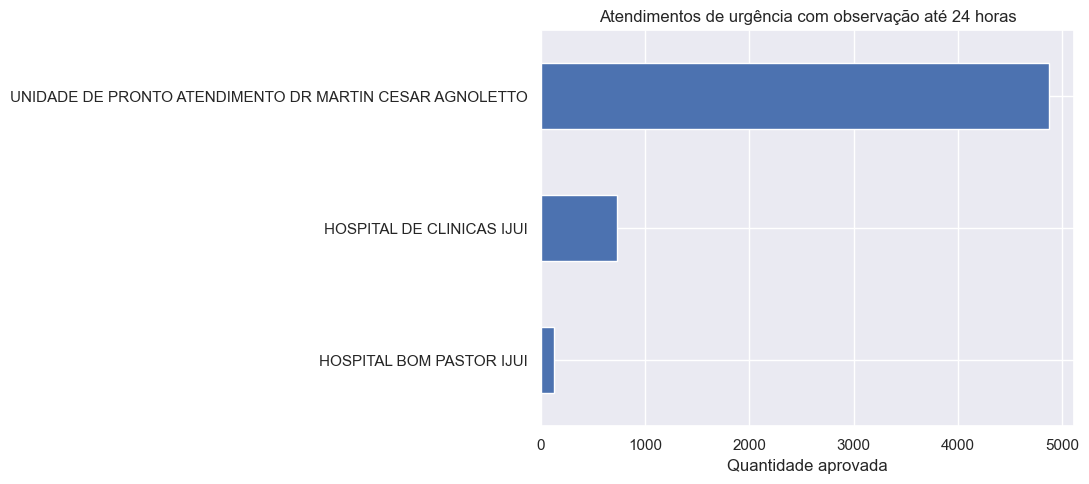

In [114]:
observacao = resumo_por_estabelecimento(detalhe[detalhe["Procedimento"].str.contains("OBSERVACAO", na=False)])
display(observacao)

grafico_top(observacao, "QuantidadeAprovada", "Atendimentos de urgência com observação até 24 horas", "Quantidade aprovada")

### 6.5 Qual faz mais atendimento básico? Quanto dura?
Atendimento básico = procedimentos de complexidade **1 - Atenção Básica** (`pa_nivcpl = '1'`). A duração não pode ser calculada: o SIA não tem horário de início e fim do atendimento. Seria preciso o e-SUS APS ou o prontuário eletrônico.

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorAprovado
7,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,208,6966,6966,0.0
3,CISA,16,4586,4586,0.0
0,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,143,863,863,0.0
1,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,93,622,622,0.0
2,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,36,245,245,0.0
6,SAMU 192 SB46 IJUI,15,194,194,0.0
5,SAMU 192 SA16 IJUI,64,188,188,0.0
4,HOSPITAL DE CLINICAS IJUI,4,62,62,0.0


Procedimentos básicos mais realizados:


,QuantidadeAprovada
Procedimento,
AFERICAO DE PRESSAO ARTERIAL,4775
CONSULTA MEDICA EM ATENCAO PRIMARIA,2705
PRIMEIRA CONSULTA ODONTOLOGICA PROGRAMATICA,2076
GLICEMIA CAPILAR,1455
ESCUTA INICIAL / ORIENTACAO (ACOLHIMENTO A DEMANDA ESPONTANEA),839
INALACAO / NEBULIZACAO,740
CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA ATENCAO PRIMARIA (EXCETO MEDICO),609
CURATIVO SIMPLES,132
SELAMENTO PROVISORIO DE CAVIDADE DENTARIA,57


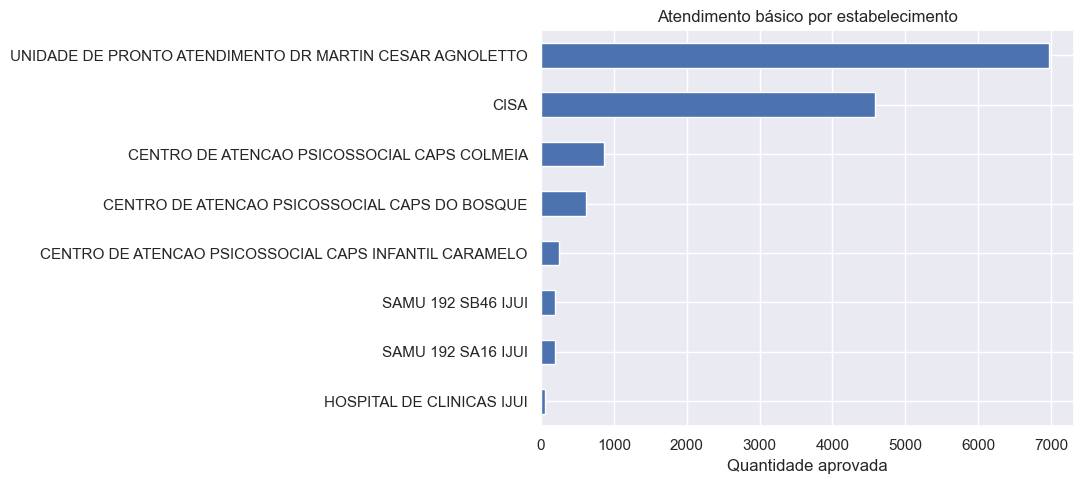

In [115]:
basico = detalhe[detalhe["pa_nivcpl"] == "1"]
resumo_basico = resumo_por_estabelecimento(basico)
display(resumo_basico)

print("Procedimentos básicos mais realizados:")
display(
    basico.groupby("Procedimento")["pa_qtdapr"].sum()
    .sort_values(ascending=False).head(10).to_frame("QuantidadeAprovada")
)

grafico_top(resumo_basico, "QuantidadeAprovada", "Atendimento básico por estabelecimento", "Quantidade aprovada")

### 6.6 De onde é a população atendida e qual a faixa etária?
* **Cidade:** município de residência do paciente (`pa_munpcn`).
* **Bairro:** não existe no SIA. O bairro do estabelecimento viria da `cadgerrs`, mas o campo está vazio para os estabelecimentos de Ijuí.
* **Faixa etária:** só registros individualizados.

Atenção básica: 223 registros com município, 96.4% de Ijuí


,Registros
MunicipioPaciente,
IJUI,215
TRES DE MAIO,1
JOIA,1
SAO JOSE DO RIO CLARO,1
SANTO ANGELO,1
VALINHOS,1
CAXIAS DO SUL,1
BOZANO,1
SANTIAGO,1


Bairros dos estabelecimentos:


,Registros
BairroEstabelecimento,
Não informado,68827


Faixa etária na atenção básica:


,Registros
FaixaEtaria,
0-17,14
18-39,76
40-59,82
60-79,37
80+,14


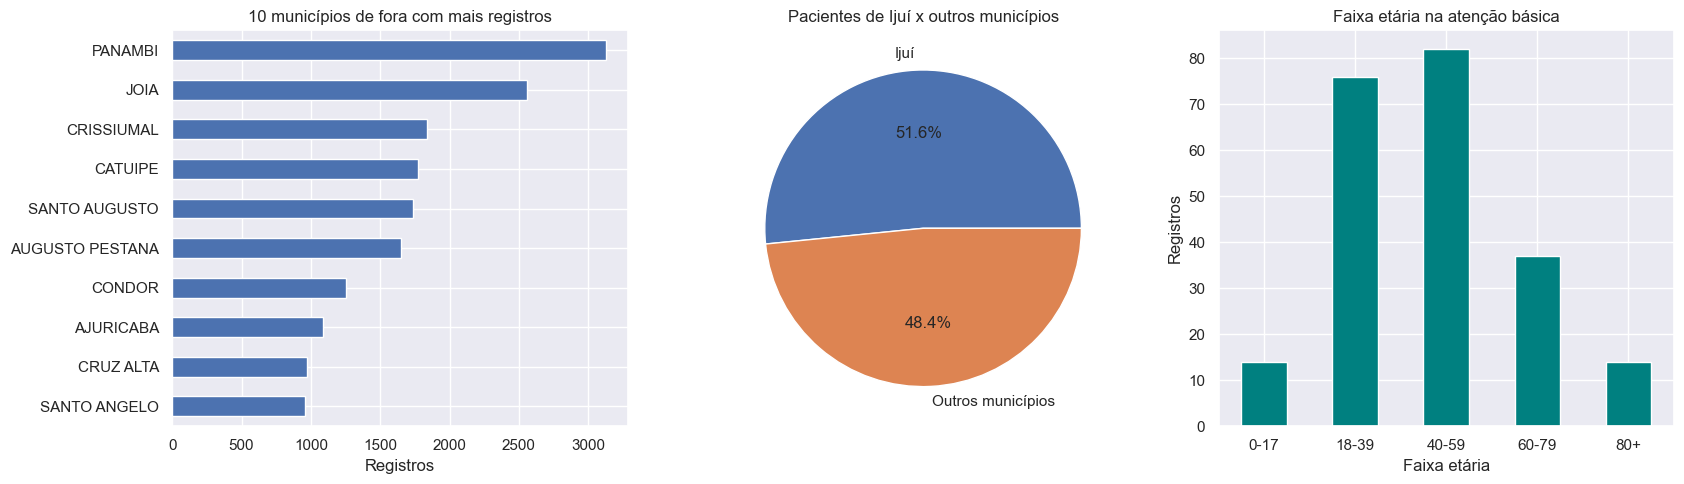

In [116]:
basico_informado = basico[basico["MunicipioPaciente"] != "Não informado"]
origem_basico = basico_informado["MunicipioPaciente"].value_counts()
print(f"Atenção básica: {len(basico_informado)} registros com município, "
      f"{origem_basico.get('IJUI', 0) / len(basico_informado) * 100:.1f}% de Ijuí")
display(origem_basico.head(10).to_frame("Registros"))

print("Bairros dos estabelecimentos:")
display(detalhe["BairroEstabelecimento"].value_counts().head(5).to_frame("Registros"))

print("Faixa etária na atenção básica:")
display(basico["FaixaEtaria"].value_counts().sort_index().to_frame("Registros"))

origem_geral = detalhe.loc[detalhe["MunicipioPaciente"] != "Não informado", "MunicipioPaciente"]
origem_geral = origem_geral.where(origem_geral == "IJUI", "Outros municípios").replace("IJUI", "Ijuí")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

detalhe.loc[detalhe["MunicipioPaciente"] != "Não informado", "MunicipioPaciente"].value_counts()     .drop("IJUI", errors="ignore").head(10).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("10 municípios de fora com mais registros")
axes[0].set_xlabel("Registros")
axes[0].set_ylabel("")

origem_geral.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Pacientes de Ijuí x outros municípios")
axes[1].set_ylabel("")

basico["FaixaEtaria"].value_counts().sort_index().plot(kind="bar", ax=axes[2], color="teal")
axes[2].set_title("Faixa etária na atenção básica")
axes[2].set_xlabel("Faixa etária")
axes[2].set_ylabel("Registros")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

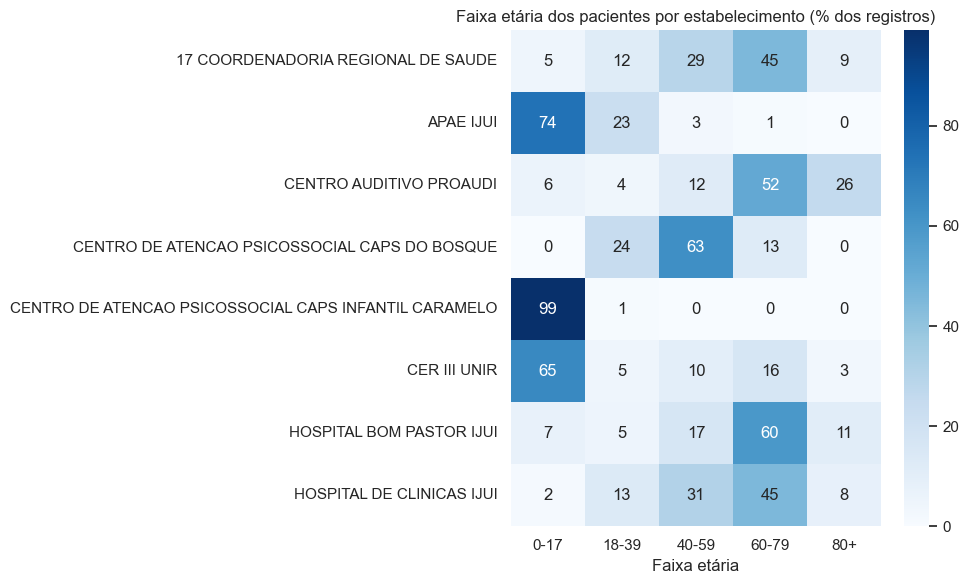

In [117]:
principais = detalhe["Estabelecimento"].value_counts().head(8).index
faixas_estab = pd.crosstab(
    detalhe.loc[detalhe["Estabelecimento"].isin(principais), "Estabelecimento"],
    detalhe["FaixaEtaria"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(faixas_estab, annot=True, fmt=".0f", cmap="Blues")
plt.title("Faixa etária dos pacientes por estabelecimento (% dos registros)")
plt.xlabel("Faixa etária")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.7 Qual a faixa de renda?
O SIA não tem renda. Para isso seria preciso cruzar o endereço do paciente com o **CadÚnico** ou com a renda do **Censo IBGE** por setor censitário. O único dado social disponível é raça/cor, mostrado abaixo só para registros com a informação.

,% dos registros
RacaCor,
Branca,93.7
Parda,4.4
Preta,1.0
Amarela,0.7
Indígena,0.2


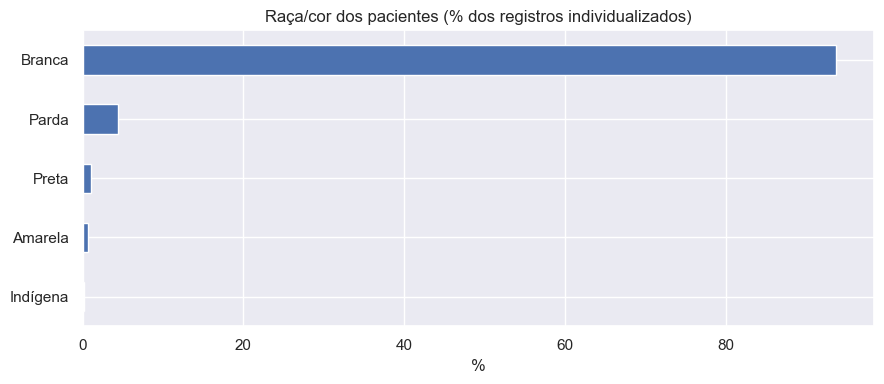

In [118]:
raca_cor = detalhe.loc[individual, "RacaCor"].value_counts(normalize=True).mul(100).round(1)
display(raca_cor.to_frame("% dos registros"))

raca_cor.sort_values().plot(kind="barh", figsize=(9, 4))
plt.title("Raça/cor dos pacientes (% dos registros individualizados)")
plt.xlabel("%")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.8 Quem tem os maiores valores apresentados e não aprovados?
Valor não aprovado = valor apresentado (`pa_valpro`) − valor aprovado (`pa_valapr`). O percentual mostra o peso da glosa no faturamento de cada estabelecimento: um valor alto em um hospital grande pode pesar menos do que um valor menor em uma clínica pequena. Valores negativos indicam aprovação acima do apresentado.

,Estabelecimento,ValorApresentado,ValorAprovado,NaoAprovado,PercentualNaoAprovado
11,HOSPITAL DE CLINICAS IJUI,3566157.48,3443895.19,122262.29,3.4
8,CISA,217267.85,167357.92,49909.93,23.0
1,APAE IJUI,56243.61,46207.05,10036.56,17.8
0,17 COORDENADORIA REGIONAL DE SAUDE,929283.76,923000.40,6283.36,0.7
17,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,68317.20,65916.54,2400.66,3.5
7,CER III UNIR,166463.49,165457.59,1005.90,0.6
5,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,4002.10,4002.10,0.00,0.0
6,CENTRO DE REFERENCIA REGIONAL EM SAUDE DO TRAB...,680.48,680.48,0.00,0.0
4,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4624.20,4624.20,0.00,0.0
3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,9161.82,9161.82,0.00,0.0


Procedimentos com maior valor não aprovado:


,Estabelecimento,Procedimento,NaoAprovado
1084,HOSPITAL DE CLINICAS IJUI,TOMOGRAFIA COMPUTADORIZADA DE TORAX,54427.59
676,HOSPITAL BOM PASTOR IJUI,MAPEAMENTO DE RETINA,26445.84
777,HOSPITAL DE CLINICAS IJUI,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,23448.60
779,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,16370.00
626,HOSPITAL BOM PASTOR IJUI,BIOMICROSCOPIA DE FUNDO DE OLHO,12216.60
183,APAE IJUI,ATENDIMENTO / ACOMPANHAMENTO DE PACIENTE EM RE...,10036.56
353,CISA,DOSAGEM DE 25 HIDROXIVITAMINA D,9113.52
872,HOSPITAL DE CLINICAS IJUI,EXAME ANATOMO-PATOLOGICO PARA CONGELAMENTO / P...,7258.84
673,HOSPITAL BOM PASTOR IJUI,GONIOSCOPIA,6679.34
740,HOSPITAL DE CLINICAS IJUI,ATENDIMENTO DE URGENCIA C/ OBSERVACAO ATE 24 H...,6197.59


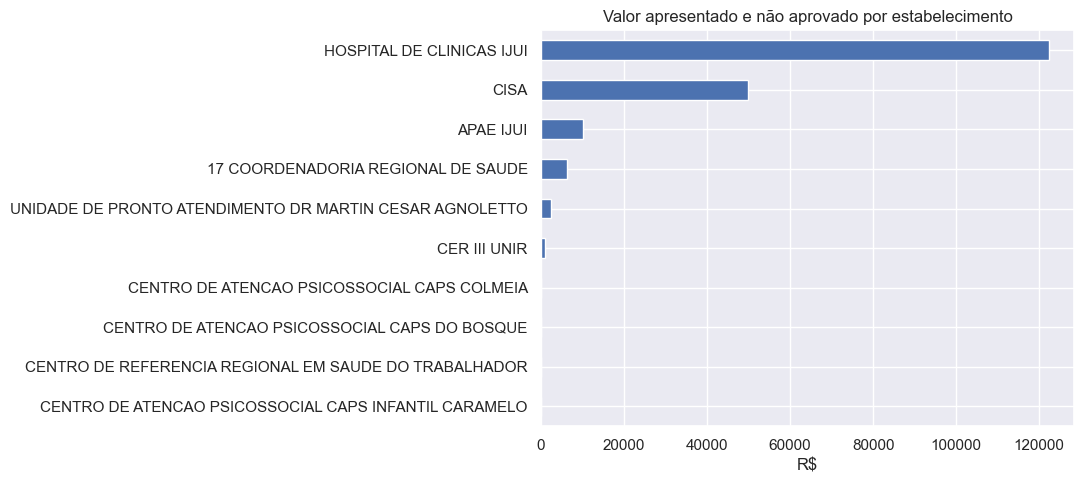

In [119]:
glosas = (
    detalhe.groupby("Estabelecimento", as_index=False)
    .agg(ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"),
         NaoAprovado=("NaoAprovado", "sum"))
    .sort_values("NaoAprovado", ascending=False)
)
glosas["PercentualNaoAprovado"] = (glosas["NaoAprovado"] / glosas["ValorApresentado"] * 100).round(1)
display(glosas.head(10).round(2))

print("Procedimentos com maior valor não aprovado:")
display(
    detalhe.groupby(["Estabelecimento", "Procedimento"], as_index=False)["NaoAprovado"].sum()
    .sort_values("NaoAprovado", ascending=False).head(10).round(2)
)

grafico_top(glosas, "NaoAprovado", "Valor apresentado e não aprovado por estabelecimento", "R$")

### 6.9 Principais achados (julho de 2026)
* **Emergências:** pelo caráter de atendimento, o **Hospital de Clínicas de Ijuí** concentra a urgência (8.920 procedimentos apresentados, 5.479 aprovados). Contando os procedimentos de urgência, a **UPA Dr. Martin Cesar Agnoletto** lidera, com 4.871 observações de até 24 horas.
* **Cirurgias ambulatoriais:** o **HCI** faz mais em quantidade (841), mas o **Hospital Bom Pastor** recebe o maior valor (cerca de R$ 354 mil), por fazer procedimentos mais caros.
* **Internação:** não dá para responder com o SIA; é preciso o SIH.
* **Atendimento básico:** quase não aparece no SIA porque as UBS informam no SISAB. Dentro do SIA, a UPA (aferição de pressão, consulta em atenção primária) e o CISA lideram.
* **Faixa etária:** nos hospitais (HCI e Bom Pastor) predominam pacientes de 60 a 79 anos (45% e 60% dos registros); APAE, CER III e CAPS Infantil atendem principalmente crianças e adolescentes.
* **Origem:** cerca de metade dos registros com município informado é de moradores de Ijuí, o que confirma o papel de polo regional da cidade.
* **Valores não aprovados:** o **HCI** tem o maior valor absoluto (cerca de R$ 122 mil, 3,4% do apresentado), puxado pela tomografia de tórax (R$ 54 mil); proporcionalmente, o **CISA** (23%) e a **APAE** (18%) são os mais afetados.
* **Faltam para o gestor:** SIH (internações), SISAB (atenção básica e duração), endereço do paciente (bairro) e CadÚnico/IBGE (renda), além de mais meses de dados para ver tendência.